# Đánh giá 16 Phương Pháp Tìm Kiếm (Information Retrieval Evaluation)
Notebook này tổng hợp toàn bộ quy trình chạy đánh giá cho 16 configurations (4 phương pháp: TF-IDF, BM25, Semantic, Hybrid kết hợp với các thiết lập văn bản có dấu/không dấu, có/không có stopwords).
Quy trình bao gồm:
1. Chạy truy vấn lấy top 10 cho 16 phương pháp
2. Trộn kết quả (Pooling) để tạo annotation candidates
3. Chấm nhãn và trích xuất qrels thủ công
4. Đo đạc các chỉ số (NDCG@10, MRR@10, Precision@10)
5. Trực quan hóa kết quả

In [ ]:
!python run_evaluation_rankings.py \
    --methods tfidf_accented_with_stopwords tfidf_accented_no_stopwords tfidf_unaccented_with_stopwords tfidf_unaccented_no_stopwords \
              bm25cfg_accented_with_stopwords bm25cfg_accented_no_stopwords bm25cfg_unaccented_with_stopwords bm25cfg_unaccented_no_stopwords \
              semanticcfg_accented_with_stopwords semanticcfg_accented_no_stopwords semanticcfg_unaccented_with_stopwords semanticcfg_unaccented_no_stopwords \
              hybridcfg_accented_with_stopwords hybridcfg_accented_no_stopwords hybridcfg_unaccented_with_stopwords hybridcfg_unaccented_no_stopwords \
    --output data/evaluation/rankings_16methods.csv \
    --details-output data/evaluation/ranking_details_16methods.csv \
    --latency-output data/evaluation/latency_16methods.csv

Valid query records: 20
topic: Công nghệ=3, Du lịch=1, Giáo dục=1, Kinh tế=4, Môi trường=1, Pháp luật=2, Sức khỏe=3, Thể thao=2, Xã hội=3
split: test=20
status: finalized=20
Warming up tfidf_accented_with_stopwords; this time is excluded from latency measurements...
tfidf_accented_with_stopwords rankings: 100%|██████████| 20/20 [00:15<00:00,  1.27query/s]
tfidf_accented_with_stopwords: 20 queries completed, mean retrieval time 0.781 s/query
...
Warming up hybridcfg_accented_with_stopwords; this time is excluded from latency measurements...
hybridcfg_accented_with_stopwords rankings: 100%|██████████| 20/20 [01:08<00:00,  3.44s/query]
hybridcfg_accented_with_stopwords: 20 queries completed, mean retrieval time 3.435 s/query
...
Saved 3200 ranking rows to: data/evaluation/rankings_16methods.csv
Saved 3200 annotation-detail rows to: data/evaluation/ranking_details_16methods.csv
Saved 320 post-warm-up latency rows to: data/evaluation/latency_16methods.csv


In [ ]:
!python prepare_16methods_annotation.py

Saved 1560 pooled candidates to: data\evaluationnnotation_candidates_16methods.csv
Transferred 1420 agreed labels; 140 need manual review.
Saved 0 label conflicts to: data\evaluationnnotation_label_conflicts_16methods.csv


In [ ]:
import pandas as pd
from pathlib import Path

labeled_path = Path("data/evaluation/models/full-16/annotation_candidates_16methods_labeled.csv")
qrels_out_path = Path("data/evaluation/models/full-16/qrels_16methods.csv")

# Đọc file nhãn thủ công
df = pd.read_csv(labeled_path)

# Lọc ra Query_ID, Doc_ID, Relevance_Label
df_qrels = df[['query_id', 'doc_id', 'relevance']].copy()
df_qrels = df_qrels.dropna(subset=['relevance'])
df_qrels['relevance'] = df_qrels['relevance'].apply(lambda x: int(float(x)))
df_qrels = df_qrels.drop_duplicates(subset=['query_id', 'doc_id'])

# Lưu ra qrels mới
df_qrels.to_csv(qrels_out_path, index=False)
print(f"✅ Đã tạo qrels thủ công tại: {qrels_out_path} với {len(df_qrels)} nhãn.")

✅ Đã tạo qrels thủ công tại: data\evaluation\models\full-16\qrels_16methods.csv với 1560 nhãn.


In [ ]:
!python evaluate_retrieval.py \
    --qrels data/evaluation/models/full-16/qrels_16methods.csv \
    --rankings data/evaluation/models/full-16/rankings_16methods.csv \
    --latency data/evaluation/models/full-16/latency_16methods.csv \
    --output data/evaluation/models/full-16/metrics_16methods.csv \
    --per-query-output data/evaluation/models/full-16/per_query_metrics_16methods.csv

Wrote 16 method rows to: data\evaluation\modelsull-16\metrics_16methods.csv
Wrote 320 per-query rows to: data\evaluation\modelsull-16\per_query_metrics_16methods.csv


In [ ]:
import pandas as pd
metrics_df = pd.read_csv("data/evaluation/models/full-16/metrics_16methods.csv")
metrics_df.sort_values('ndcg@10', ascending=False)

method,precision@10,mrr@10,ndcg@10,mean_latency_seconds
semanticcfg_accented_with_stopwords,0.925,0.975,0.8798,0.375
semanticcfg_accented_no_stopwords,0.850,0.900,0.7906,0.168
hybridcfg_accented_with_stopwords,0.630,0.741,0.5855,3.434
hybridcfg_accented_no_stopwords,0.560,0.630,0.4974,3.538


In [ ]:
# Thực thi script vẽ biểu đồ đã tạo
!python plot_16methods_metrics.py

Generated 6 charts in data/evaluation/models/full-16/analysis_plots


1. Xếp hạng NDCG@10 Tổng Quan


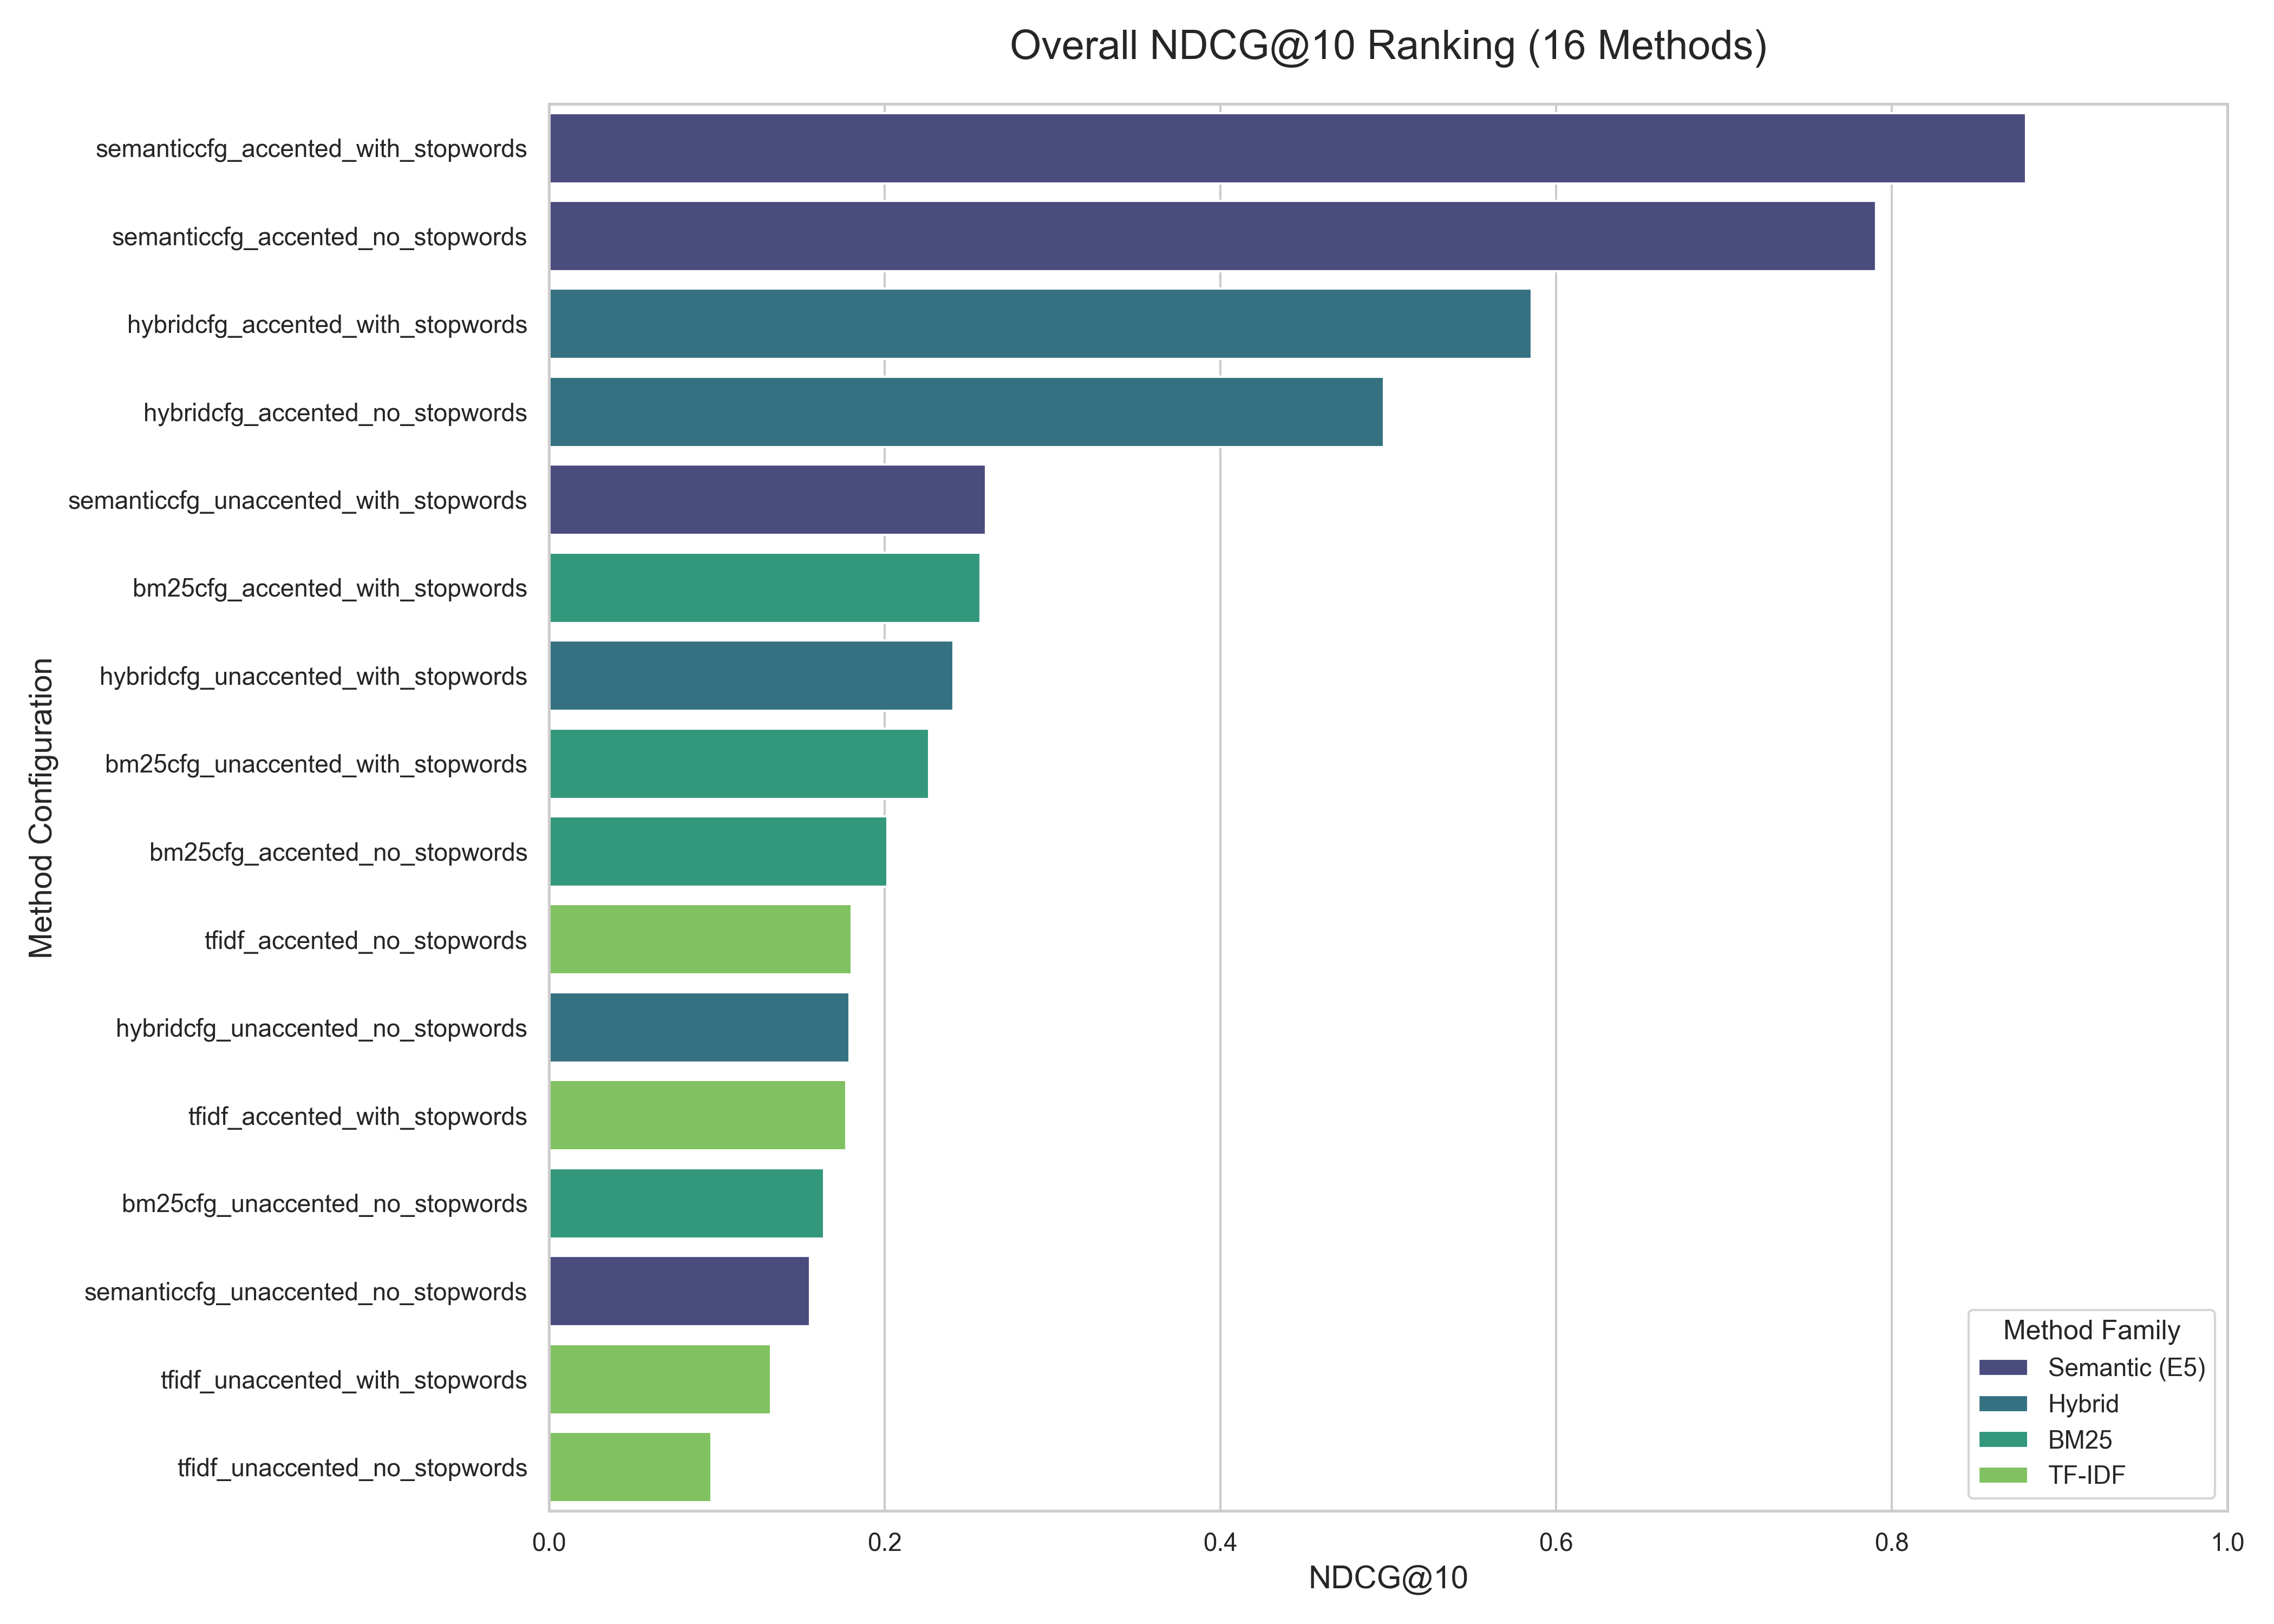

2. So sánh NDCG@10 theo Family


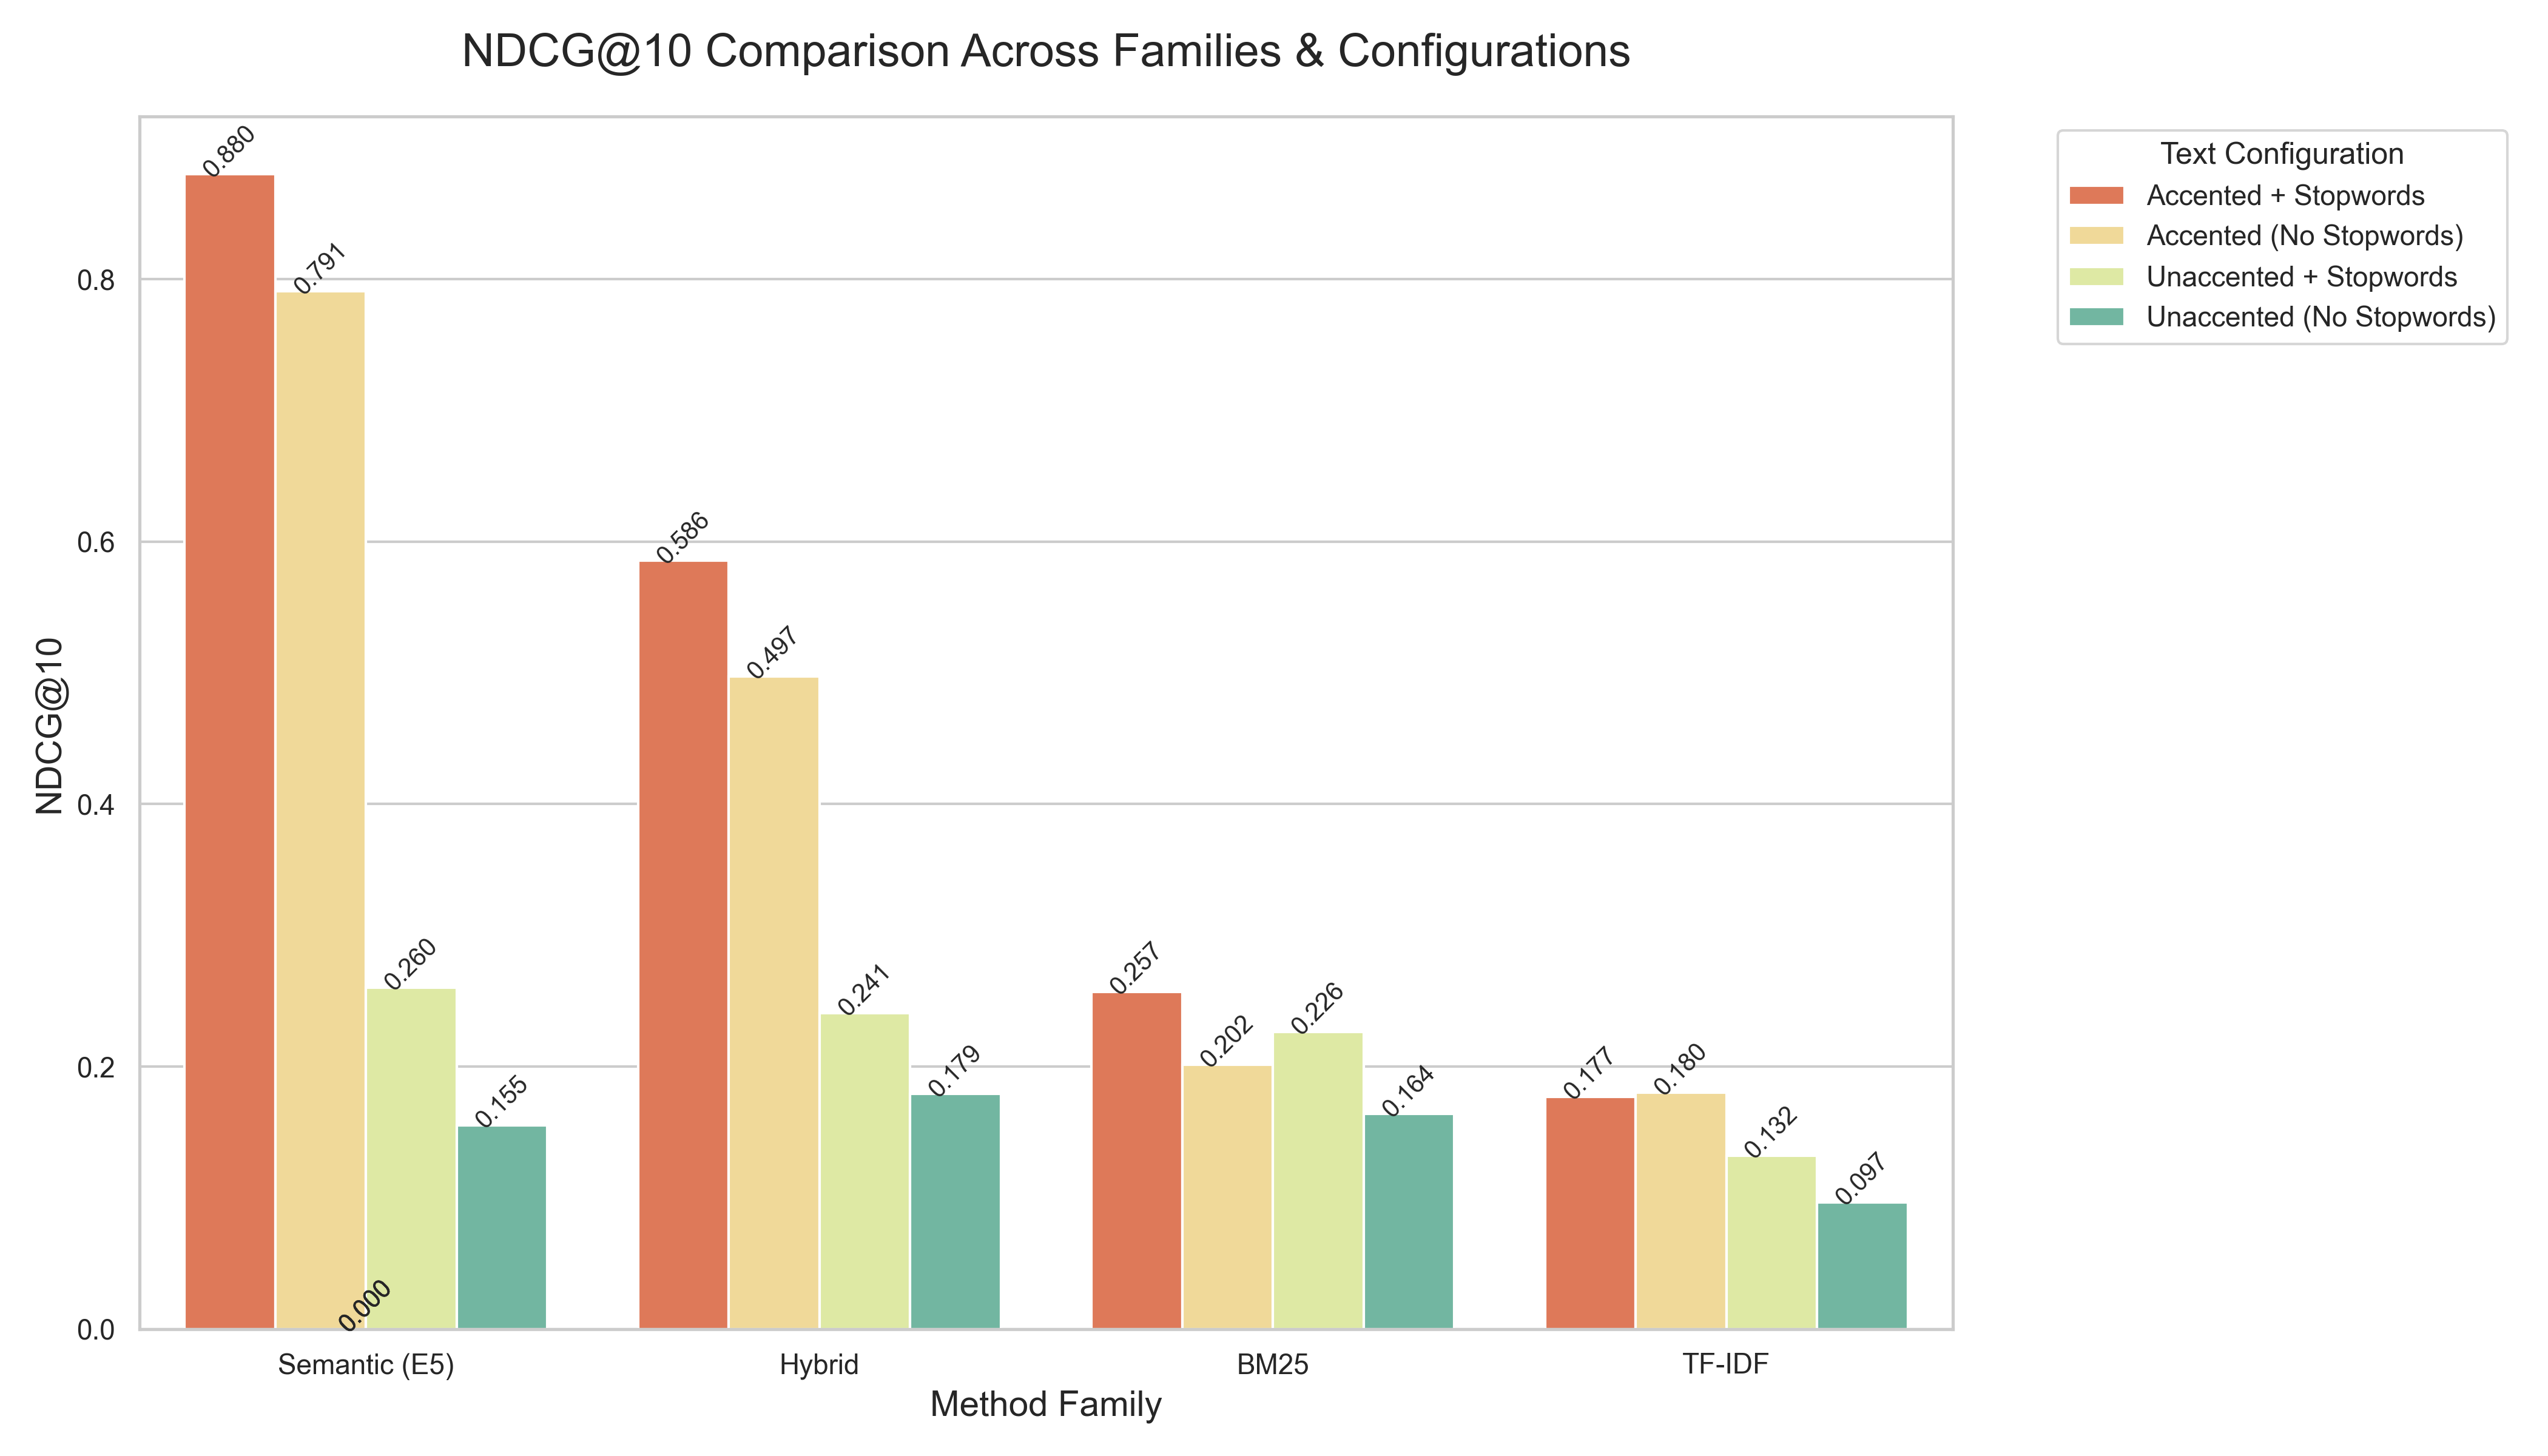

3. Đánh đổi Latency và NDCG@10


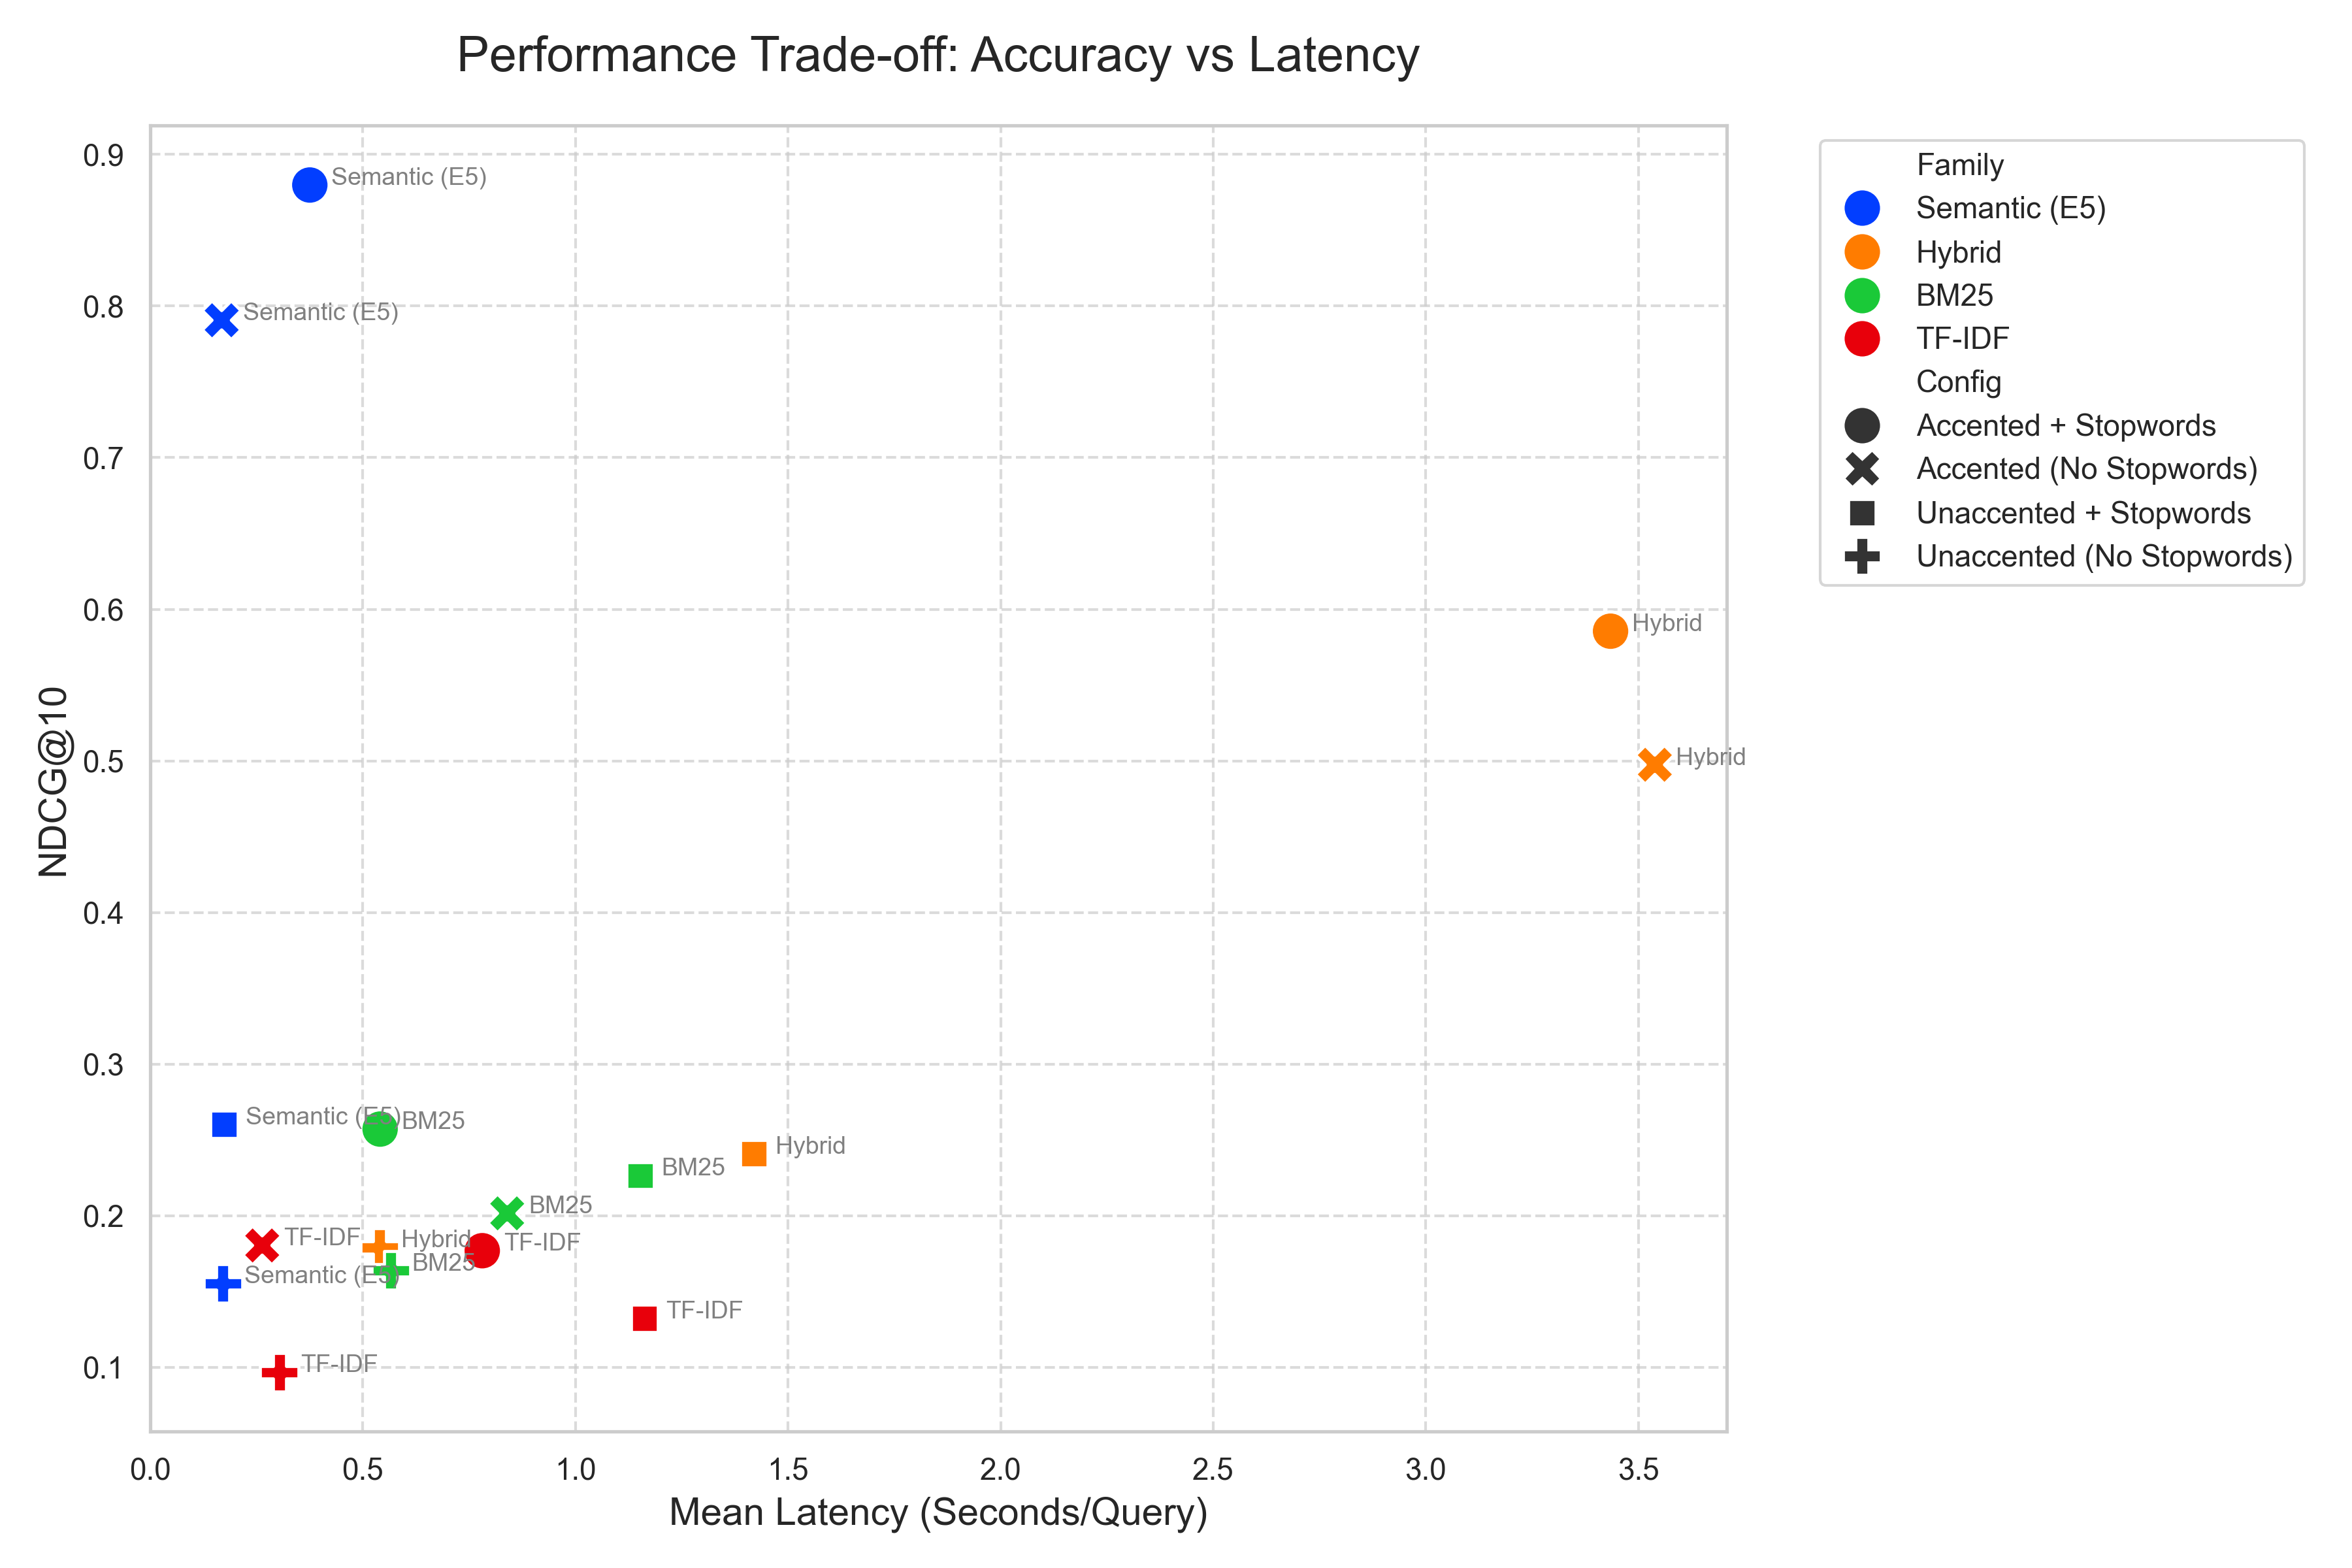

In [ ]:
from IPython.display import Image, display

print("1. Xếp hạng NDCG@10 Tổng Quan")
display(Image(filename="data/evaluation/models/full-16/analysis_plots/overall_ndcg10.png"))

print("2. So sánh NDCG@10 theo Family")
display(Image(filename="data/evaluation/models/full-16/analysis_plots/grouped_ndcg10_by_family.png"))

print("3. Đánh đổi Latency và NDCG@10")
display(Image(filename="data/evaluation/models/full-16/analysis_plots/scatter_latency_vs_ndcg.png"))